# 5. VISUALIZACIONES estrellas


Para realizar las visualizaciones correspondientes para checkear nuestra hipotesis:
Se necesitan hacer diferentes variables intermedias y agrupaciones algo complicadas.
Ademas tengo que hacer y llamar una funcion en los diferentes calculos de diferentes visualizaciones, para rellenar los graficos numericamente

In [22]:
def etiquetas(ax, total):
    for barras in ax.containers:
        ax.bar_label(barras,fmt=lambda n: f"{n:.0f} ({n / total:.1%})",padding=3)

        

Carga de archivos

In [23]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

if ROOT.name == "jupyter":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CLEAN = ROOT / "CLEAN"
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.calculos_visualizaciones.funciones import etiquetas

CSV_FILE =  "dataset_merged.csv"
df = pd.read_csv(CLEAN / "dataset_merged.csv")

Variables necesarias

In [24]:
planetas = df.drop_duplicates(subset=["hostname", "pl_name"]).copy()
sistemas = planetas.drop_duplicates(subset="hostname").copy()
orden = sorted(sistemas["sy_pnum"].unique())

### 6. Temperatura y luminosidad según el tipo espectral

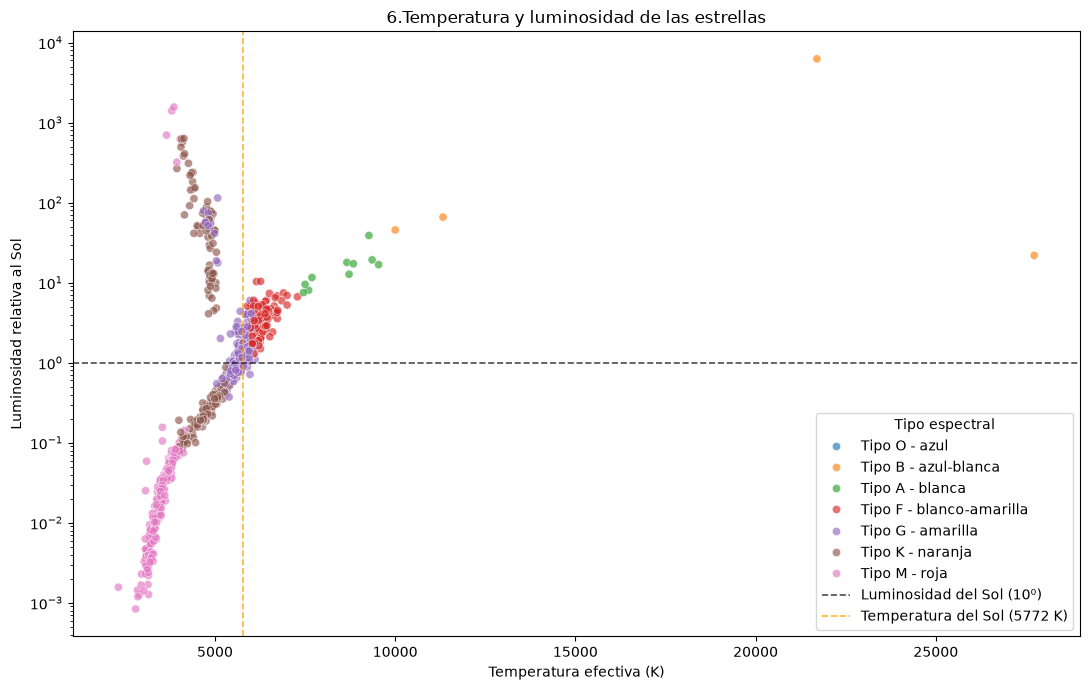

In [25]:
estrellas_grafico = sistemas.dropna(subset=["st_teff_y", "st_rad"]).copy()

estrellas_grafico = estrellas_grafico[
    (estrellas_grafico["st_teff_y"] > 0)& (estrellas_grafico["st_rad"] > 0)]

estrellas_grafico["luminosidad_relativa"] = (
    estrellas_grafico["st_rad"] ** 2* (estrellas_grafico["st_teff_y"] / 5772) ** 4)

estrellas_grafico["tipo_espectral"] = (
    estrellas_grafico["st_spectype"].str.extract(r"^([OBAFGKM])", expand=False))

nombres_tipos_espectrales = {
    "O": "Tipo O - azul",
    "B": "Tipo B - azul-blanca",
    "A": "Tipo A - blanca",
    "F": "Tipo F - blanco-amarilla",
    "G": "Tipo G - amarilla",
    "K": "Tipo K - naranja",
    "M": "Tipo M - roja"}

estrellas_grafico["tipo_espectral_nombre"] = (
    estrellas_grafico["tipo_espectral"].map(nombres_tipos_espectrales))

estrellas_grafico = estrellas_grafico.dropna(subset=["tipo_espectral"])

plt.figure(figsize=(11, 7))

sns.scatterplot(data=estrellas_grafico,x="st_teff_y",y="luminosidad_relativa",hue="tipo_espectral_nombre",hue_order=list(nombres_tipos_espectrales.values()),alpha=0.65,s=35)

plt.yscale("log")
plt.axhline(y=10 ** 0,color="black",linestyle="--",linewidth=1.2,alpha=0.7,label="Luminosidad del Sol (10⁰)")
plt.axvline(x=5772,color="orange",linestyle="--",linewidth=1.2,alpha=0.8,label="Temperatura del Sol (5772 K)")

plt.title("6.Temperatura y luminosidad de las estrellas")
plt.xlabel("Temperatura efectiva (K)")
plt.ylabel("Luminosidad relativa al Sol")
plt.legend(title="Tipo espectral")
plt.savefig(ROOT / "imagenes" /"6. Temperatura y luminosidad según el tipo espectral.png",dpi=300,bbox_inches="tight")

plt.tight_layout()
plt.show()


### 7. Sistemas con estrellas parecidas al Sol

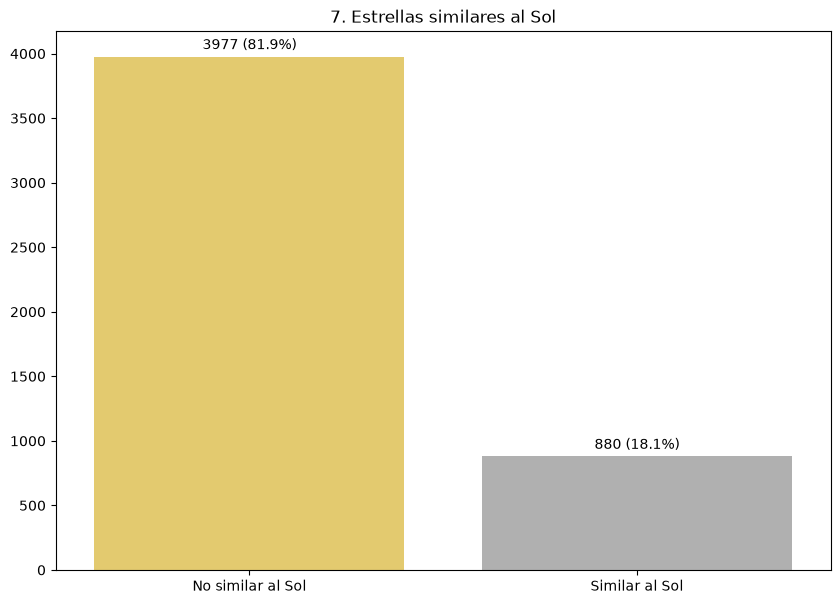

In [ ]:
sistemas["similar_al_sol"] = (sistemas["st_teff_y"].between(5500, 6050) &sistemas["st_rad"].between(0.85, 1.15) &sistemas["st_mass_y"].between(0.85, 1.15))
conteo_solares = sistemas["similar_al_sol"].map({True: "Similar al Sol", False: "No similar al Sol"}).value_counts()

colores=["#F6D55C", "#B0B0B0"]

plt.figure(figsize=(10, 7))
sns.barplot( x=conteo_solares.index ,y=conteo_solares.values ,hue=conteo_solares.index,palette=colores)
plt.title("7. Estrellas similares al Sol",)
plt.xlabel("")
etiquetas(plt.gca(), conteo_solares.sum())
plt.savefig(ROOT / "imagenes" /"7. Frecuencia de estrellas parecidas al Sol.png",dpi=300,bbox_inches="tight")

plt.show()



 ### 8. Analogos terrestres alrededor de estrellas similares al Sol
 Criterio: estrella similar al Sol, planeta 0.8 - 1.25 R_tierra y en HZ.

C:\Users\AItor\AppData\Local\Temp\ipykernel_23764\1009615883.py:36: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.barplot( x=conteo_analogos.index ,y=conteo_analogos.values ,


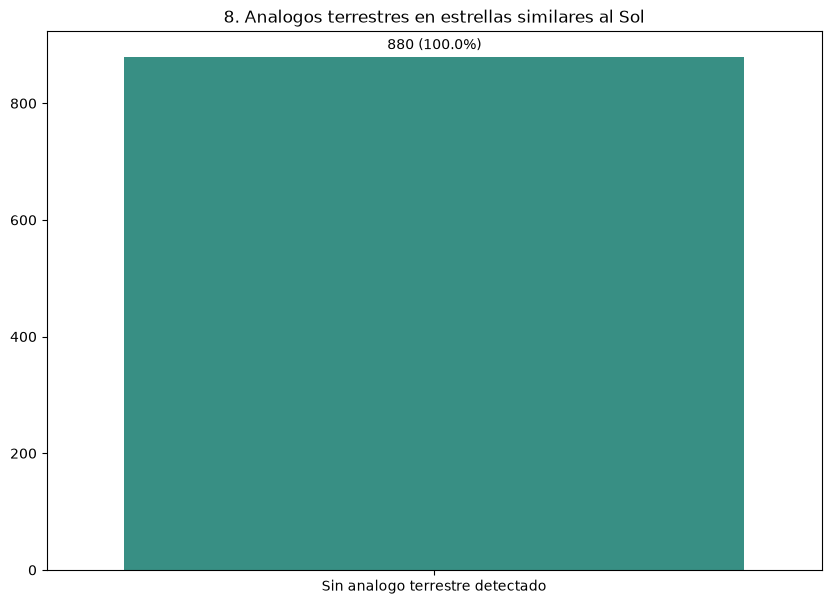

In [29]:
validos_orbita = ((df["st_mass_y"] > 0) & (df["st_mass_y"] < 100) &(df["pl_orbper_y"] > 0))
df["a_ua"] = float("nan")
df.loc[validos_orbita, "a_ua"] = (df.loc[validos_orbita, "st_mass_y"]
* (df.loc[validos_orbita, "pl_orbper_y"] / 365.25) ** 2) ** (1 / 3)
temperatura_sol = 5772

validos_estrella = ((df["st_teff_y"] > 0) & (df["st_rad"] > 0))

df["luminosidad_relativa"] = float("nan")
df.loc[validos_estrella, "luminosidad_relativa"] = (df.loc[validos_estrella, "st_rad"] ** 2
* (df.loc[validos_estrella, "st_teff_y"] / temperatura_sol) ** 4)
df["zh_interior"] = 0.95 * df["luminosidad_relativa"] ** 0.5
df["zh_exterior"] = 1.67 * df["luminosidad_relativa"] ** 0.5

df["en_zh"] = ((df["a_ua"] >= df["zh_interior"]) &(df["a_ua"] <= df["zh_exterior"]))

df["estrella_similar_al_sol"] = (
    df["st_teff_y"].between(5500, 6050) &
    df["st_rad"].between(0.85, 1.15) &
    df["st_mass_y"].between(0.85, 1.15)
)
df["analogo_tierra"] = (
    df["estrella_similar_al_sol"] &
    df["pl_rade_y"].between(0.8, 1.25) &
    df["en_zh"]
)
sistemas_solares = df[df["estrella_similar_al_sol"]].groupby("hostname")
analogos_por_sistema = sistemas_solares["analogo_tierra"].any()
conteo_analogos = analogos_por_sistema.map(
    {True: "Con analogo terrestre", False: "Sin analogo terrestre detectado"}
).value_counts()

colores=["#2A9D8F", "#B0B0B0"]

plt.figure(figsize=(10, 7))
sns.barplot( x=conteo_analogos.index ,y=conteo_analogos.values ,
            hue=conteo_analogos.index,palette=colores)

plt.title("8. Analogos terrestres en estrellas similares al Sol")
plt.xlabel("")
plt.ylabel("")
etiquetas(plt.gca(), conteo_analogos.sum())
plt.savefig(ROOT / "imagenes" /"8. Analogos terrestres alrededor de estrellas similares al Sol.png",dpi=300,bbox_inches="tight")
plt.show()